In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import xarray as xr

from fast_o3_iv import utils, metrics
import fast_o3_iv.bias_correction as bc
from fast_o3_iv.config import INTERIM_DATA_DIR
from fast_o3_iv.modeling.train import DatasetConfig


In [3]:
# load observation osdma8
ramp_osdma8 = xr.open_dataset((
        INTERIM_DATA_DIR
        / "RAMP"
        / "Jacob_wRAMP_OSDMA8_1990_2017.nc"))


In [4]:
# load modeled monthly mda8o3
config_hist = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )

config_ssp = DatasetConfig(
            source_id = config_hist.source_id,
            cmip_experiment_id = 'ssp245',
            variable_setname = config_hist.variable_setname,
            year_range = range(2015,2055)
        )



In [5]:
mode = "testing"
model_key = "GPR-local"

In [6]:
hist_anm = utils.load_or_aggregate_results(
    mode,
    config_hist,
     model_key,
)

ssp_anm = utils.load_or_aggregate_results(
   mode,
    config_ssp,
    model_key,
)

No existing dataset found. Creating it now.
Found 11 parquet files
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2-WACCM6/historical/wa6_ic1.003/setC/GPR-local/NCAR.CESM2-WACCM6.historical.wa6_ic1.003.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2-WACCM6/historical/wa6_ic1.004/setC/GPR-local/NCAR.CESM2-WACCM6.historical.wa6_ic1.004.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2-WACCM6/historical/wa6_ic1.005/setC/GPR-local/NCAR.CESM2-WACCM6.historical.wa6_ic1.005.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2-WACCM6/historical/wa6_ic2.001/setC/GPR-local/NCAR.CESM2-WACCM6.historical.wa6_ic2.001.setC.1975-2014.GPR-local.parquet
/home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/member_results/NCAR/CESM2-WACCM6/histo

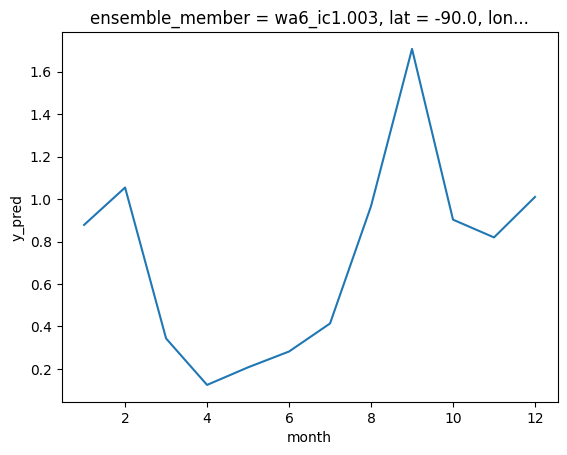

In [7]:
# check that seasonal cycle is removed from original anomalies
hist_anm['y_pred'].isel(ensemble_member=0, lat=0, lon=0).groupby('time.month').mean().plot()

In [8]:
# add climatology (only required if target == mda8o3_anm (setC))

train_config_hist = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = config_hist.variable_setname,
            year_range = range(1975,2015)
        )
train_config_ssp = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = config_ssp.cmip_experiment_id,
            variable_setname = config_hist.variable_setname,
            year_range = range(2015,2055)
        )

hist = utils.add_mda8o3_climatology(hist_anm, train_config_hist) 
ssp = utils.add_mda8o3_climatology(ssp_anm, train_config_ssp) 

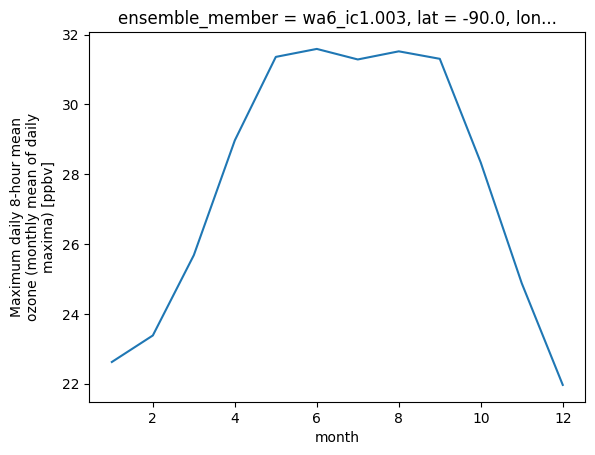

In [9]:
# check that seasonal cycle is fixed
hist['y_pred'].isel(ensemble_member=0, lat=0, lon=0).groupby('time.month').mean().plot()

In [10]:
#convert monthly mda8o3 to osdma8 
hist_osdma8 = metrics.calc_osdma8(hist)
ssp_osdma8 = metrics.calc_osdma8(ssp)

In [11]:
# calculate scaling factor based on historical mod vs obs osdma8
scaling_factor, obs_base, mod_base = bc.get_bc_scaling_factor(hist_osdma8, ramp_osdma8)

In [12]:
# apply bias correction
hist_osdma8_bc = bc.bias_correct(hist_osdma8, scaling_factor)
ssp_osdma8_bc = bc.bias_correct(ssp_osdma8, scaling_factor)

In [13]:
# save to netcdf
file_path = bc.return_osdma8_bc_path(mode, config_hist, model_key)
hist_osdma8_bc.to_netcdf(file_path)

file_path = bc.return_osdma8_bc_path(mode, config_ssp, model_key)
ssp_osdma8_bc.to_netcdf(file_path)